In [1]:
import random
import tensorflow as tf
import matplotlib.pyplot as plt

# Import MINST data
from tensorflow.examples.tutorials.mnist import input_data
mnist = input_data.read_data_sets("/tmp/data/", one_hot=True)

Extracting /tmp/data/train-images-idx3-ubyte.gz
Extracting /tmp/data/train-labels-idx1-ubyte.gz
Extracting /tmp/data/t10k-images-idx3-ubyte.gz
Extracting /tmp/data/t10k-labels-idx1-ubyte.gz


In [2]:
# Parameters
learning_rate = 0.1
training_epochs = 25
batch_size = 100
display_step = 5

In [3]:
# tf graph input
x = tf.placeholder(tf.float32, [None, 784])
y = tf.placeholder(tf.float32, [None, 10])

# Set model weights
W = tf.Variable(tf.zeros([784, 10]))
b = tf.Variable(tf.zeros([10]))

# Construct model
hyphothesis = tf.nn.softmax(tf.matmul(x, W) + b)

# Minimize error using cross entropy
cost = tf.reduce_mean(-tf.reduce_sum(y * tf.log(hyphothesis), reduction_indices = 1))

# Gradient Descent
optimizer = tf.train.GradientDescentOptimizer(learning_rate).minimize(cost)

# Initializing the variables
init = tf.initialize_all_variables()

epoch: 0005 cost = 0.311490830
epoch: 0010 cost = 0.287584490
epoch: 0015 cost = 0.277342744
epoch: 0020 cost = 0.270768657
epoch: 0025 cost = 0.266015669
optimization finished
accuracy: 0.898
label: [6]
prediction: [6]


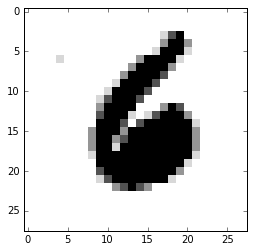

In [4]:
# Launch the graph
with tf.Session() as sess:
    sess.run(init)
    
    # Training cycle
    for epoch in range(training_epochs):
        avg_cost = 0.
        total_batch = int(mnist.train.num_examples / batch_size)
        
        # Loop over all batches
        for i in range(total_batch):
            batch_xs, batch_ys = mnist.train.next_batch(batch_size)
            
            # Fit training using batch data
            _, batch_cost = sess.run([optimizer, cost], feed_dict = {x: batch_xs, y: batch_ys})

            # Compute average cost sess.run(cost, feed_dict = {x: batch_xs, y: batch_ys})
            avg_cost += batch_cost / total_batch
            
        # Display logs per epoch step
        if (epoch + 1) % display_step == 0:
            print('epoch:', '%04d' % (epoch + 1), 'cost =', '{:.9f}'.format(avg_cost))
            
    print('optimization finished')
    
    # Test model
    correct_prediction = tf.equal(tf.argmax(hyphothesis, 1), tf.argmax(y, 1))
    
    # Caculate accuracy for 3000 examples
    accuracy = tf.reduce_mean(tf.cast(correct_prediction, tf.float32))
    print('accuracy:', sess.run(accuracy, feed_dict = {x: mnist.test.images[:3000], y: mnist.test.labels[:3000]}))
    
    # Get one and preduct
    r = random.randint(0, mnist.test.num_examples - 1)
    print('label:', sess.run(tf.argmax(mnist.test.labels[r:r+1], 1)))
    print('prediction:', sess.run(tf.argmax(hyphothesis, 1), {x: mnist.test.images[r:r+1]}))
    
    # Show the img
    plt.imshow(mnist.test.images[r:r+1].reshape(28, 28), cmap = 'Greys', interpolation = 'nearest')
    plt.show()